# 候选传导链检验复跑记录
FICC and ECS candidate-chain validation · 2026-10-16

## tl;dr
22条链逐条核对；8条完成两项统计检验，NSCC-02A及03B达到卡片门槛。前者是市场量与未交割余额关联，后者的分期、变化量和多重检验结果较弱。其余链保留案例、缺口与待定定义。没有已验证的因果关系或最终风险评分。

## Context & Methods
按提供的主卡片执行，主结果用同季度；旧试跑与改变量、改信号、改时滞的结果单列。框架为S×V，业务相关性在传导链入口核实，不乘E。

### Key Assumptions
阈值、事件窗口、区块长度及OFR变量的可用性修订见`analysis_plan.json`及两份修订记录。MBS的2022事件窗在计算前按下半年处理。所有已见历史均为探索性样本，不是盲测。V不作为检验二的结果变量。

In [1]:
from pathlib import Path
import sys,json,contextlib,io
import pandas as pd,numpy as np
ROOT=Path.cwd()
if not (ROOT/'analysis_plan.json').exists():
    ROOT=ROOT/'capstone_database/Capstone_Project/risk_business_ml/transmission_chain_tests_2026_10_16'
assert (ROOT/'analysis_plan.json').exists()
sys.path.insert(0,str(ROOT/'src'))
pd.set_option('display.max_colwidth',75)
from IPython.display import display
plan=json.loads((ROOT/'analysis_plan.json').read_text())
print(plan['version'])
print(plan['framework'])

candidate-cards-v1-execution-2026-10-16
Risk priority = channel-specific external shock S times internal vulnerability V. Business relevance and chain applicability are evidence gates, not a separate E multiplier. Missing vulnerability is not zero and does not permit a complete risk score.


## Data
冻结的仓库输入在`inputs/`，新抓取的官方原件在`raw/`，单元格、日期对齐及逐对数据在`data/`。主PQD样本截至2026Q2；FTD原件有2018年1月至2026年9月210个半月文件。FRED直连失败时，房贷和CP/TBill分别使用原始发布方Freddie Mac及美联储的数据，映射及定义保存在来源记录。

In [2]:
manifest=json.loads((ROOT/'run_manifest.json').read_text())
display(pd.DataFrame(manifest['signal_ranges']).T.rename_axis('signal'))
coverage=pd.read_csv(ROOT/'data/sec_ftd_file_coverage.csv')
assert coverage.file.nunique()==210
ftd_daily=pd.read_csv(ROOT/'data/sec_ftd_daily.csv',parse_dates=['date'])
assert not ftd_daily.date.duplicated().any()
assert pd.Timestamp('2026-05-15') in set(ftd_daily.date)
print('SEC source files:',len(coverage),'security-day rows:',int(coverage.records.sum()),'daily balances:',len(ftd_daily))

,n,first,last
signal,,,
ust10_abs_change,2193,2018-01-03,2026-10-09
sofr_effr_adjusted,2004,2018-10-01,2026-10-13
baa_widen20,2170,2018-01-31,2026-10-09
vix,2240,2018-01-02,2026-10-13
vix_jump,2220,2018-01-31,2026-10-13
mortgage_spread_change,457,2018-01-11,2026-10-08
cp_bill_spread,1555,2018-01-02,2026-10-13
equity_volume,2209,2018-01-02,2026-10-15


SEC source files: 210 security-day rows: 11464312 daily balances: 2185


## Results
### 1 Recompute card definitions
重新计算信号、事件筛选、季度关联、区块区间及OFR回归。此步骤只读本包冻结输入，不访问网络；不会替换任何原项目模型。

In [3]:
import run_numeric_tests
with contextlib.redirect_stdout(io.StringIO()):
    signals,responses=run_numeric_tests.run()
results=pd.read_csv(ROOT/'results/quarterly_test_results.csv')
primary=results[results.label.eq('primary')]
display(primary[['chain_id','outcome','n','rho','ci_low','ci_high','rho_changes','rho_later','bh_q_primary','pass_card']].round(3))

,chain_id,outcome,n,rho,ci_low,ci_high,rho_changes,rho_later,bh_q_primary,pass_card
0,FICC-GSD-01,im_qoq,22,0.408,-0.014,0.764,0.186,-0.147,0.119,False
1,ECS-NSCC-01A,im_call_to_prior_im,22,0.195,-0.241,0.609,0.316,0.086,0.577,False
2,ECS-NSCC-01B,vm_peak_to_avg,23,0.081,-0.359,0.493,-0.334,0.029,0.713,False
3,ECS-NSCC-01C,backtest_breaches,23,0.414,-0.067,0.689,0.095,0.257,0.119,False
4,ECS-NSCC-03B,im_call_to_im,23,0.454,0.197,0.680,0.154,0.086,0.119,True
5,FICC-MBSD-01,vm_peak_qoq,22,0.150,-0.157,0.594,0.081,-0.086,0.607,False


### 2 Show uncertainty
下图给出全部六项季度主检验，不隐藏未达门槛的结果。95%区间来自四季度配对移动区块bootstrap，2000次；多数区间跨零。相关系数不是风险系数或损失概率。

Matplotlib is building the font cache; this may take a moment.


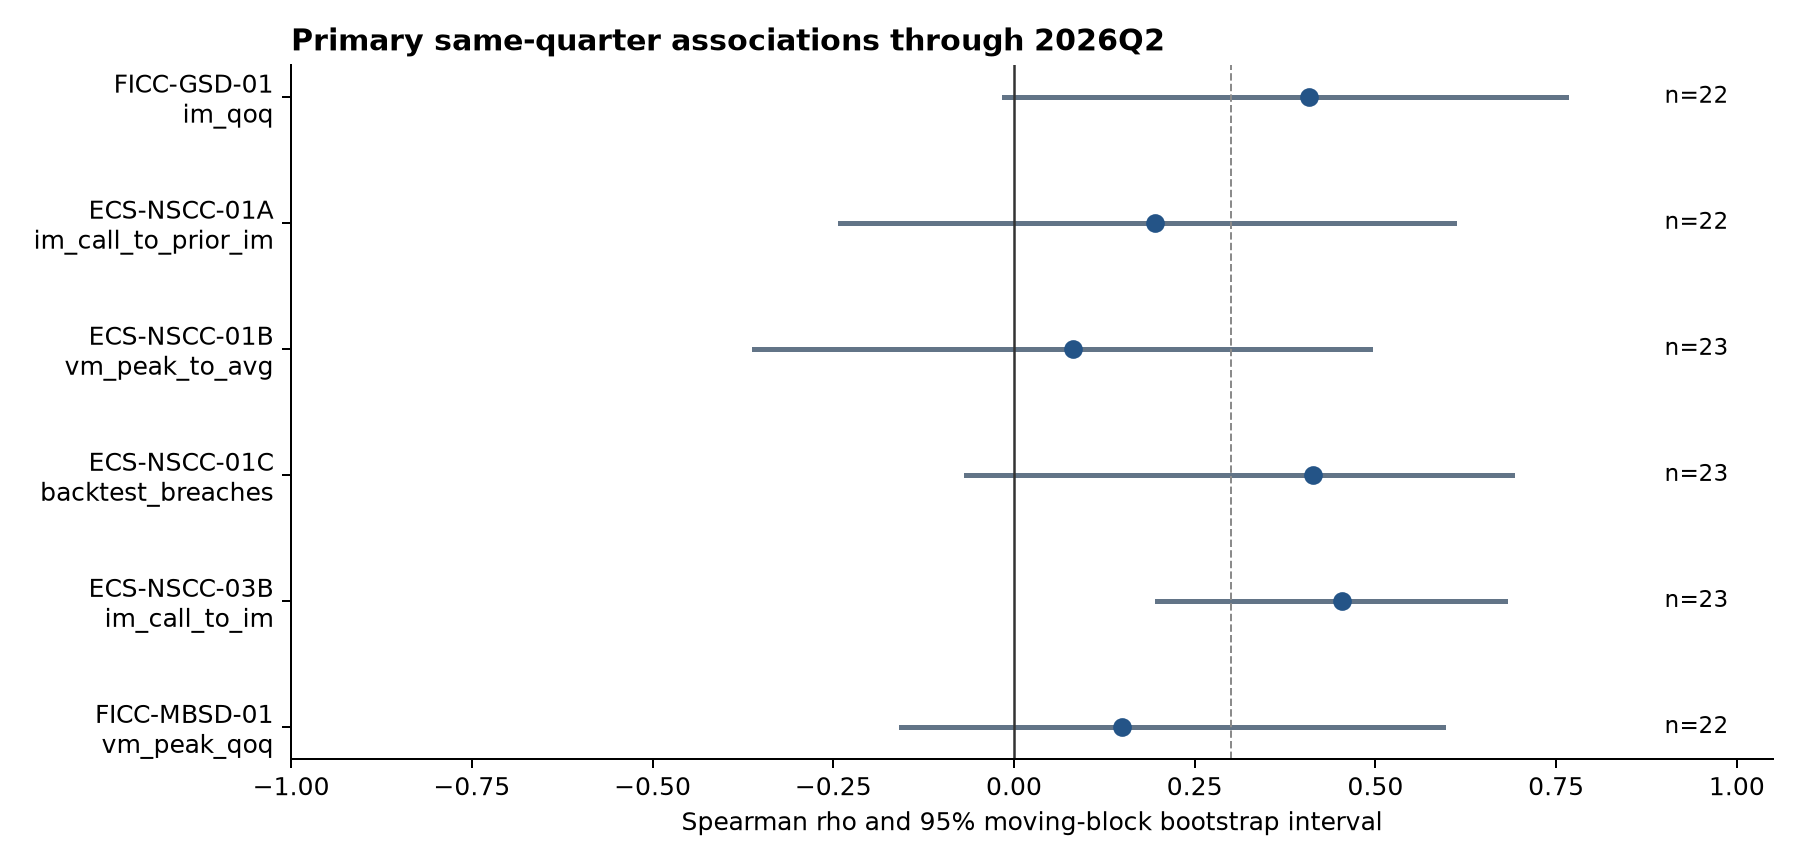

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(10,4.8))
labels=primary.chain_id+'\n'+primary.outcome
y=np.arange(len(primary))
for i,row in enumerate(primary.itertuples()):
    ax.plot([row.ci_low,row.ci_high],[i,i],color='#627487',lw=2)
    ax.scatter(row.rho,i,color='#245487',s=42,zorder=3)
    ax.text(.9,i,f'n={row.n}',va='center',ha='left',fontsize=9)
ax.axvline(0,color='#333333',lw=1)
ax.axvline(.3,color='#8b8b8b',ls='--',lw=.8)
ax.set_yticks(y,labels);ax.invert_yaxis();ax.set_xlim(-1,1.05)
ax.set_xlabel('Spearman rho and 95% moving-block bootstrap interval')
ax.set_title('Primary same-quarter associations through 2026Q2',loc='left',fontweight='bold')
fig.tight_layout()
(ROOT/'figures').mkdir(exist_ok=True)
fig.savefig(ROOT/'figures/primary_quarterly_intervals.png',dpi=180)
from IPython.display import Image
display(Image(filename=str(ROOT/'figures/primary_quarterly_intervals.png')));plt.close(fig)

### 3 Recompute the volume and FTD association
SEC字段是每日未交割存量；按周求日均余额，不跨日求和。主回归控制月末、季末，HAC滞后4个有效周观测。结果不是NSCC系统容量的因果效应。原始安全日数据的汇总可由`src/analyze_ftd.py`重建；下格从保存的日度汇总重新估计回归。

In [5]:
from fit_equity_ftd import fit_volume_ftd
ftd_result=fit_volume_ftd()
display(pd.DataFrame([{k:v for k,v in ftd_result.items() if k!='source_quality_flags'}]).T.rename(columns={0:'value'}))
ofr=json.loads((ROOT/'results/ofr_funding_hac.json').read_text())
display(pd.DataFrame([ofr])[['chain_id','n','shock_days','coefficient_bp','hac_p','pass_card']].round(4))

,value
chain_id,ECS-NSCC-02A
n_weeks,413
shock_weeks,150
first_week,2018-06-30/2018-07-06
last_week,2026-09-19/2026-09-25
coefficient_million_outstanding_shares,30.404069
hac_p,0.000013
ci_low,16.725973
ci_high,44.082166
pass_card,True


,chain_id,n,shock_days,coefficient_bp,hac_p,pass_card
0,FICC-GSD-02,246,46,0.021,0.9757,False


### 4 Event screening and variants
ECS R1新窗口与10月6日旧窗口不同，不能把新通过解释成模型改进。下一季度、VIX跳升和VM替换保留为次要探索，不能覆盖主卡片。

In [6]:
events=pd.read_csv(ROOT/'results/event_test_summary.csv')
display(events[['test_key','mode','events_hit','events_available','non_event_alarm_proxy','status']].round(3))
display(results[results.label.ne('primary')][['chain_id','label','outcome','lag','rho','ci_low','ci_high','rho_changes']].round(3))

,test_key,mode,events_hit,events_available,non_event_alarm_proxy,status
0,FICC-GSD-01,weekly,3,3,0.122,PASS
1,FICC-GSD-02,weekly,3,3,0.124,PASS
2,FICC-GSD-04,weekly,2,2,0.111,PASS
3,FICC-MBSD-01,weekly,2,3,0.115,PASS
4,ECS-R1,daily,3,4,0.077,PASS
5,ECS-NSCC-03A,weekly,2,2,0.111,PASS
6,ECS-NSCC-03B,weekly,4,4,0.119,PASS
7,ECS-DTC-04,weekly,1,2,0.101,FAIL
8,ECS-R2,daily,4,4,0.134,PASS
9,ECS-R1-legacy-events,daily,2,3,0.082,PASS


,chain_id,label,outcome,lag,rho,ci_low,ci_high,rho_changes
6,FICC-GSD-01,secondary_next_quarter,im_qoq,1,0.464,-0.122,0.715,0.093
7,ECS-NSCC-01A,secondary_next_quarter,im_call_to_prior_im,1,-0.221,-0.574,0.115,-0.134
8,ECS-NSCC-01B,secondary_next_quarter,vm_peak_to_avg,1,0.125,-0.158,0.630,0.315
9,ECS-NSCC-01C,secondary_next_quarter,backtest_breaches,1,0.468,-0.139,0.760,-0.087
10,ECS-NSCC-03B,secondary_next_quarter,im_call_to_im,1,0.516,0.012,0.812,0.179
11,FICC-MBSD-01,secondary_next_quarter,vm_peak_qoq,1,0.000,-0.255,0.452,0.099
12,ECS-NSCC-01A,secondary_changed_definition,im_call_to_im,0,0.060,-0.418,0.455,0.067
13,ECS-NSCC-01A,secondary_changed_definition,im_call_to_im,1,-0.224,-0.609,0.025,-0.350
14,ECS-NSCC-01B,secondary_changed_definition,vm_peak_to_avg,0,0.340,-0.158,0.668,-0.340
15,ECS-NSCC-01B,secondary_changed_definition,vm_peak_to_avg,1,0.478,0.116,0.792,0.456


### 5 Chain coverage and gaps
完整状态表包括22条链。两份原始候选文件仍保留；CSV可直接复制到其汇总表。

In [7]:
summary=pd.read_csv(ROOT/'results/chain_status_CN.csv')
assert len(summary)==22 and summary['编号'].is_unique
for group in ['FICC','ECS']:
    display(summary[summary['编号'].str.startswith(group)][['编号','执行范围','卡片置信度','仍需补充']])
assert (summary['执行范围']=='两项统计已跑').sum()==8
assert sum(primary.pass_card)==1
assert ftd_result['pass_card'] and not ofr['pass_card']
print('Checks passed:22chains,8complete numerical executions,2card-gate passes.')

,编号,执行范围,卡片置信度,仍需补充
0,FICC-GSD-01,两项统计已跑,证据不足,NaN
1,FICC-GSD-02,两项统计已跑,证据不足,更多可比清算回购利率或GSD支付反应证据
2,FICC-GSD-03,事件与描述核对,Medium 机制及描述,真实接入与未来合规节点结果；V的19.1.3仅近5季度有数值
3,FICC-GSD-04,信号与历史案例核对,Medium 案例,更近的会员事件与业务直接证据
4,FICC-MBSD-01,两项统计已跑,证据不足,NaN
5,FICC-GSD-05,事件核对完成 结果待补,Low,客户迁移、同口径份额；脆弱度定义
6,FICC-GSD-06,案例与PQD字段部分完成,Low 直接证据不足,GSD直接服务影响、会员依赖和可比运营口径
7,FICC-MBSD-02,来源核对 结果未跑,Low,明确改革节点、FINRA授权或官方导出、MBSD反应


,编号,执行范围,卡片置信度,仍需补充
8,ECS-NSCC-01A,两项统计已跑,证据不足,NaN
9,ECS-NSCC-01B,两项统计已跑,证据不足,NaN
10,ECS-NSCC-01C,两项统计已跑,证据不足,NaN
11,ECS-NSCC-02A,两项统计已跑,High 按卡片门槛,容量脆弱度与共同趋势/其他混杂控制
12,ECS-NSCC-02B,检验一已跑 检验二未跑,Medium 仅信号,NSCC独立故障及容量指标
13,ECS-NSCC-03A,信号与历史案例核对,Medium 案例,NaN
14,ECS-NSCC-03B,两项统计已跑,High 按卡片门槛,NaN
15,ECS-NSCC-04,事件及即时证据核对,Low 至 Medium,连续NSCC月度失败率、V与其他制度节点
16,ECS-NSCC-05,数据补齐 检验未跑,待定,权威事件日历、成功标准及V
17,ECS-DTC-01,事件及即时证据核对,Low 至 Medium,连续DTC非CNS月度失败率与V


Checks passed:22chains,8complete numerical executions,2card-gate passes.


## Takeaways
保留NSCC成交量链的研究支持；对资金追缴链继续验证稳定性。GSD利率链、MBSD房贷代理链与VIX主卡片尚未达两检门槛。案例、定义或业务标签不足的链继续保留缺口。

完整解读见`精简检验汇总_CN.md`；案例、HTTP失败及来源哈希均随包保存。新未见季度及更多业务直接证据才可以继续评估可靠性；不凭一个季度或单一相关系数赋权。